In [1153]:
import re
import ast
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [1228]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, MultiLabelBinarizer, LabelEncoder
from category_encoders import BinaryEncoder
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTENC

In [1231]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report, f1_score

<div style="
    background: linear-gradient(135deg, #4E7A56 0%, #6D9773 55%, #95B89A 100%); 
    border-radius: 8px; 
    padding: 16px 24px; 
    margin: 12px 0; 
    text-align: left;
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;
    box-shadow: 0 3px 10px rgba(78, 122, 86, 0.2);
">
    <h2 style="
        color: #FFFFFF; 
        margin: 0; 
        font-size: 1.4em; 
        font-weight: 700;
        letter-spacing: 0.3px;
        text-align: left;
    ">
        Data Exploration
    </h2>
</div>


In [1156]:
df = pd.read_csv('wargon_thrift.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29535 entries, 0 to 29534
Data columns (total 35 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   filename          29535 non-null  object 
 1   image_type        29535 non-null  object 
 2   brand_missing     29535 non-null  bool   
 3   sizetext          1582 non-null   object 
 4   cut               29535 non-null  object 
 5   stains            10637 non-null  object 
 6   price             29535 non-null  object 
 7   smell             1642 non-null   object 
 8   price_confidence  22595 non-null  object 
 9   damage3           1950 non-null   object 
 10  season            25342 non-null  object 
 11  condition         29535 non-null  int64  
 12  usage_confidence  22595 non-null  object 
 13  damage3loc        4839 non-null   object 
 14  annotator         29535 non-null  float64
 15  pattern           15760 non-null  object 
 16  comment           4550 non-null   object

##### **Zenodo Second-Hand Clothing Dataset Column Definitions**

#### **1. File & Annotation Metadata**
* **`filename`** (`object`, 30,192 non-null): Unique image file identifier or path (typically formatted with an item ID and view suffix).
* **`image_type`** (`object`, 30,192 non-null): Camera angle represented by the row (`front`, `back`, or `brand` label close-up).
* **`brand_missing`** (`bool`, 30,192 non-null): Flags whether the close-up `brand` label image file is missing (`True` if the garment had no label or if the image was removed due to visible hands/faces).
* **`annotator`** (`float64`, 30,192 non-null): Numeric ID of the human sorter/annotator who labeled the item.
* **`comment`** (`object`, 4,648 non-null): Free-text notes added by the sorter for edge cases, unusual defects, or clarifications.

##### ***2. Garment Identity & Styling Attributes***
* **`category`** (`object`, 30,192 non-null): High-level garment group (e.g., *Tops*, *Bottoms*, *Outerwear*, *Dresses*).
* **`type`** (`object`, 30,192 non-null): Specific garment subtype within the category (e.g., *T-shirt*, *Jeans*, *Blazer*, *Sweater*).
* **`cut`** (`object`, 30,192 non-null): Stringified multi-label list combining **fit** (`Regular`, `Loose`, `Tight`, `Oversize`), **length** (`Cropped`, `Long`), and **neckline** (`C-collar`, `V-collar`, `Turtle neck`, `Collar`). Order reflects annotator click sequence.
* **`size`** (`object`, 24,314 non-null): Standardized garment size selected from predefined options (e.g., `S`, `M`, `L`, `XL`, or numeric EU sizes).
* **`sizetext`** (`object`, 1,653 non-null): Raw, free-text size transcribed directly from the tag when it did not match standard dropdown options.
* **`brand`** (`object`, 30,192 non-null): Standardized brand name selected from a predefined dropdown list (includes `"Unknown"` or `"Other"`).
* **`brandtext`** (`object`, 10,624 non-null): Exact free-text transcription from the brand label (used for unlisted brands, sub-brands, or partial/faded tags).
* **`colors`** (`object`, 30,192 non-null): Stringified list of primary color(s) present on the garment.
* **`pattern`** (`object`, 16,084 non-null): Surface pattern or print (e.g., *Solid*, *Striped*, *Floral*, *Checkered*); `NaN` typically indicates plain or unspecified items.
* **`season`** (`object`, 25,917 non-null): Intended wear season (e.g., *Spring/Summer*, *Autumn/Winter*, *All-year*).
* **`trend`** (`object`, 5,825 non-null): Fashion trend or style tag indicating current resale appeal.
* **`description`** (`object`, 16,219 non-null): Short free-text description summarizing garment features.

##### **3. Condition, Wear & Defect Metrics**
* **`condition`** (`int64`, 30,192 non-null): Overall garment quality rating on a **1–5 ISO scale** (`5` = like-new/mint, `1` = heavily worn/unusable).
* **`pilling`** (`int64`, 30,192 non-null): Fabric fuzz/bobble severity rated on a **1–5 ISO scale** (`5` = no pilling, `1` = severe pilling).
* **`stains`** (`object`, 10,928 non-null): Presence, type, or severity of staining (`NaN` indicates no stains recorded).
* **`holes`** (`object`, 1,844 non-null): Presence, count, or severity of unintentional holes or tears (`NaN` indicates no holes).
* **`styleholes`** (`bool`, 30,192 non-null): Distinguishes intentional distressed/ripped fashion design (`True`) from actual damage (`False`).
* **`smell`** (`object`, 1,673 non-null): Indicates odor issues (e.g., smoke, mildew, sweat); `NaN` means no odor detected.
* **`damage`**, **`damage2`**, **`damage3`** (`object`, 8,165 / 3,850 / 2,010 non-null): Up to three distinct defect types recorded on the garment (e.g., broken zipper, missing button, seam rip, fading), ordered from primary to tertiary defect.
* **`damageloc`**, **`damage2loc`**, **`damage3loc`** (`object`, 11,477 / 8,539 / 4,957 non-null): Garment location corresponding to `damage`, `damage2`, and `damage3` (e.g., *front*, *back*, *sleeve*, *collar*, *hem*).

##### **4. Physical & Material Properties**
* **`material`** (`object`, 30,114 non-null): Fiber composition (e.g., *Cotton*, *Polyester*, *Wool*, blends) measured via Near-Infrared (NIR) spectroscopy scanners.
* **`weight`** (`float64`, 30,192 non-null): Measured weight of the individual garment.

##### **5. Circular Sorting & Pricing Targets**
* **`usage`** (`object`, 30,192 non-null): Primary circular sorting decision assigned by expert sorters (*Reuse*, *Export*, *Repair*, *Remake*, *Recycle*, *Energy recovery*).
* **`usage_confidence`** (`object`, 23,124 non-null): Annotator's self-reported certainty level for the assigned `usage` pathway (`NaN` in batches where confidence logging was inactive).
* **`price`** (`object`, 30,192 non-null): Suggestive resale price or price tier (stored as `object` due to mixed formats/non-sellable markers; meant only as a rough estimate).
* **`price_confidence`** (`object`, 23,124 non-null): Annotator's confidence level in their `price` estimate.


In [1157]:
df['usage'].value_counts()

usage
Reuse      14414
Export     12275
Recycle     2808
export        16
recycle       11
reuse          9
Rcycle         2
Name: count, dtype: int64

In [1158]:
df['price'].value_counts()

price
<50        17679
50-100     10394
100-150     1462
Name: count, dtype: int64

In [1159]:
df.describe(include='all').T.iloc[:, :4]

,count,unique,top,freq
filename,29535,29505,front_2024_01_24_14_10_20.png,2
image_type,29535,2,front,14784
brand_missing,29535,2,False,27386
sizetext,1582,330,missing,144
cut,29535,152,['Regular'],15972
stains,10637,8,Minor,4465
price,29535,3,<50,17679
smell,1642,2,Minor,1340
price_confidence,22595,3,High,18732
damage3,1950,279,nopprigt,254


In [1160]:
((df.isna().sum()/df.shape[0])*100).sort_values(ascending=False)

sizetext            94.643643
smell               94.440494
holes               93.990181
damage3             93.397664
damage2             87.374302
comment             84.594549
damage3loc          83.616049
trend               80.927713
damage              73.055697
damage2loc          71.735229
brandtext           64.855256
stains              63.985102
damageloc           62.055189
pattern             46.639580
description         46.402573
usage_confidence    23.497545
price_confidence    23.497545
size                19.305908
season              14.196716
material             0.237007
brand_missing        0.000000
filename             0.000000
image_type           0.000000
price                0.000000
annotator            0.000000
condition            0.000000
cut                  0.000000
pilling              0.000000
weight               0.000000
colors               0.000000
category             0.000000
usage                0.000000
brand                0.000000
type      

<div style="
    background: linear-gradient(135deg, #4E7A56 0%, #6D9773 55%, #95B89A 100%); 
    border-radius: 8px; 
    padding: 16px 24px; 
    margin: 12px 0; 
    text-align: left;
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;
    box-shadow: 0 3px 10px rgba(78, 122, 86, 0.2);
">
    <h2 style="
        color: #FFFFFF; 
        margin: 0; 
        font-size: 1.4em; 
        font-weight: 700;
        letter-spacing: 0.3px;
        text-align: left;
    ">
        Data Cleaning
    </h2>
</div>


In [1161]:
df.columns

Index(['filename', 'image_type', 'brand_missing', 'sizetext', 'cut', 'stains',
       'price', 'smell', 'price_confidence', 'damage3', 'season', 'condition',
       'usage_confidence', 'damage3loc', 'annotator', 'pattern', 'comment',
       'material', 'pilling', 'weight', 'size', 'damage2loc', 'holes',
       'brandtext', 'colors', 'damageloc', 'description', 'trend', 'category',
       'damage2', 'usage', 'brand', 'type', 'damage', 'styleholes'],
      dtype='object')

In [1162]:
df = df.drop(columns=['filename', 'image_type', 'annotator', 'usage_confidence', 'price_confidence', 'comment', 'description',])

**`brand_missing` column:**

In [1163]:
df['brand_missing'].value_counts()

brand_missing
False    27386
True      2149
Name: count, dtype: int64

In [1164]:
df['brand_missing'].isna().sum()

np.int64(0)

**`sizetext` column:**

In [1165]:
df['sizetext'].value_counts()

sizetext
missing     144
Missing      90
130          52
32           52
150          49
           ... 
77            1
w25 l 34      1
w29 l 32      1
31 x 32       1
36x34         1
Name: count, Length: 330, dtype: int64

In [1166]:
print(df['sizetext'].nunique())
df['sizetext'].unique()

330


array([nan, 'missing', '32', '32"', 'xxxxl', '33', '3xl', '2a', 'W25 L32',
       '90', '130', 'Missing', 'w28', 'w42 l32', '31/32', 'w32', '36/34',
       '158/164', 'W29 L30', '150', '28/32', '4', '30', '14', '34/30',
       '160', '35', 'w34 l32', '120', 'W38 L32', '100', 'x38 l 32',
       'L36 W34', '60', 'w27 L29', '58', 'L/XL', '70', '48/50', '41',
       '26', 'W34 L32', 'w34 l34', 'w29 l30', 'C54', '98/104', '93/86',
       'D20/40', '31', '16', 'Blaine du nil', '1', '30/30', '134/140',
       '29', 'w32 l34', '74/80', 'w29', '158-164', '122/128', 'W L L 34',
       '37/38', 'w26', '2', '29/32', '27/30', '32/32', 'W32 L30', 'C50',
       '30/34', '51-69', 'waist 26', 'D21', '6', '39', '12 m', 'w28 l34',
       'w32 l32', 'w28 l32', '21', 'D100', '12', '110/116', '8', '18',
       '154', '7', 'W34 L28', '28', 'w30', "31''185", '4XL', 'w29 l32 ',
       '5', 'W38 L34', '30/32', '4Y', '40/42', '14-15', 'W36 L32', '102',
       '4a', 'w36 l32', 'c50', '31/30', 'Not available', 'W3

- We will use this column to infer missing values in the `size` column and then drop it.

**`cut` column:**

In [1167]:
with pd.option_context('display.max_rows', None):
    print(pd.DataFrame(df['cut'].value_counts()))

                                              count
cut                                                
['Regular']                                   15972
['Regular', 'C-collar']                        3200
['C-collar']                                   1698
['Tight']                                      1290
['Regular', 'V-collar']                         851
[]                                              845
['Loose']                                       761
['V-collar']                                    735
['Cropped']                                     519
['Regular', 'Turtle neck']                      330
['C-collar', 'Regular']                         308
['Turtle neck']                                 283
['None']                                        273
['Long']                                        209
['Regular', 'Tight']                            207
['Regular', 'Cropped']                          206
['Regular', 'Loose']                            190
['Regular', 

In [1168]:
print(df['cut'].nunique())

152


In [1169]:
df['cut'] = df['cut'].apply(lambda x: sorted([item.title() for item in ast.literal_eval(x)]))

df['cut'].apply(tuple).nunique()

90

In [1170]:
cut_tuples = df['cut'].apply(tuple)
cut_value_counts = cut_tuples.value_counts()
frequent_cuts = cut_value_counts[cut_value_counts >= 30].index

df = df[cut_tuples.isin(frequent_cuts)]

df['cut'].apply(tuple).nunique()


33

In [1171]:
df['cut'] = df['cut'].apply(lambda x: np.nan if x in ([], ['none']) else x)

#### **`stains` column:**

In [1172]:
df['stains'].value_counts()

stains
Minor    4429
Major    3191
No       1972
Yes       906
none        3
major       2
minor       1
no          1
Name: count, dtype: int64

In [1173]:
df['stains'] = df['stains'].str.lower()
df['stains'] = df['stains'].apply(lambda x: 'no stains' if x in ('no', 'none', np.nan) else x)

In [1174]:
is_yes = df['stains'] == 'yes'

df.loc[is_yes & (df['price'] == '<50'), 'stains'] = 'major'
df.loc[is_yes & (df['price'] != '<50'), 'stains'] = 'minor'

In [1175]:
df['stains'] = df['stains'].str.title()

In [1176]:
df['stains'].value_counts()

stains
No Stains    20688
Minor         4535
Major         3994
Name: count, dtype: int64

#### **`price` column:**

In [1177]:
df['price'].value_counts()

price
<50        17497
50-100     10284
100-150     1436
Name: count, dtype: int64

#### **`smell` column:**

In [1178]:
df['smell'].value_counts()

smell
Minor    1300
Major     293
Name: count, dtype: int64

In [1179]:
df['smell'] = df['smell'].replace(np.nan, 'No Smell')

#### **`season` column:**

In [1180]:
df['season'].value_counts()

season
All       21411
Summer     2130
Spring      612
Autumn      544
Winter      370
Name: count, dtype: int64

In [1181]:
df['season'] = df['season'].replace('ALL', 'All')

#### **`pattern` column:**

In [1182]:
df['pattern'].value_counts()

pattern
Other              4240
Floral print       2134
Striped            2067
Logo print         1958
Plain               913
Animal print        823
Checkered print     797
Geometric print     547
Lace                521
Embroidered         515
Dots                512
Glitter             316
Transparent         161
Metallic             94
none                  1
Name: count, dtype: int64

In [1183]:
df['pattern'] = df['pattern'].str.lower()
df['pattern'] = df['pattern'].replace('none', 'no pattern')
df['pattern'] = df['pattern'].replace(np.nan, 'no pattern')
df['pattern'] = df['pattern'].str.title()


#### **`condition` column:**

In [1184]:
df['condition'].value_counts()

condition
3    9721
5    7884
2    5971
4    4506
1    1135
Name: count, dtype: int64

#### **`material` column:**

In [1185]:
df['material'].value_counts()

material
100% cotton                                 5940
100% polyester                              2913
100% Cotton                                 2090
100% viscose                                1233
100% bomull                                 1112
                                            ... 
100% Polyester, 70% Polyester, 30% Acryl       1
75% bomull 25% acryl                           1
67%cotton 33%viscose                           1
53% visc, 47% cott                             1
100% bomuill                                   1
Name: count, Length: 2835, dtype: int64

In [1186]:
material_map = {
    'bomull': 'cotton', 'cott': 'cotton', 'cot': 'cotton', 'cotton': 'cotton',
    'poly': 'polyester', 'polyester': 'polyester',
    'vis': 'viscose', 'visc': 'viscose', 'viskos': 'viscose', 'viscose': 'viscose',
    'ull': 'wool', 'wool': 'wool',
    'akryl': 'acrylic', 'acryl': 'acrylic', 'acry': 'acrylic', 'acrylic': 'acrylic',
    'elas': 'elastane', 'elastan': 'elastane', 'elastane': 'elastane', 'lycra': 'elastane', 'spandex': 'elastane',
    'nylo': 'nylon', 'nylone': 'nylon', 'nylon': 'nylon', 'polyamide': 'nylon',
    'silke': 'silk', 'silk': 'silk',
    'acetate': 'acetate',
    'polyurethane': 'polyurethane',
    'leather': 'leather',
    'imitation leather': 'faux_leather'
}

unknown_patterns = r'unknown|unnknown|scanner can not|low signal|no match|\?'

def round_to_10(val):
    # Standard half-up rounding to nearest 10 (65 -> 70, 35 -> 40, 5 -> 10 and so on)
    return int(np.floor((val + 5) / 10.0) * 10)

def clean_and_generalize_material(val):
    if pd.isna(val):
        return np.nan
    
    text = str(val).lower().strip()
    
    # Handle unknown/unreadable entries
    if text == '' or re.search(unknown_patterns, text):
        if not re.search(r'\d+\s*%', text):
            return 'unknown'
            
    # Remove structural labels (outer, inner, lining, shell, body, )
    text = re.sub(r'\b(outer|inner|lining|shell|body|exterior|interior|shoulderstrap)\s*:\s*', ' ', text)
    
    # Fix OCR/scanner typos and comma decimals
    text = re.sub(r'\b1005\b', '100%', text)
    text = text.replace(',', '.')
    
    # Extract all (percentage, material_word) pairs
    pairs = re.findall(r'(\d+(?:\.\d+)?)\s*%\s*([a-zåäö\s]+?)(?=\d+\s*%|$|\.|,|;|\?)', text)

    # Fallback if no percentages exist 
    if not pairs:
        found_mats = []
        for raw_key, std_name in material_map.items():
            if re.search(rf'\b{raw_key}\b', text) and std_name not in found_mats:
                found_mats.append(std_name)
        
        if len(found_mats) == 1:
            return f"100% {found_mats}"
        elif len(found_mats) > 1:
            return ', '.join(sorted(found_mats))
        else:
            return 'unknown'

    
    # Aggregate raw percentages by standardized material name first
    raw_totals = {}
    for pct_str, raw_mat in pairs:
        raw_mat = raw_mat.strip()
        std_mat = None
        for key, mapped in material_map.items():
            if re.search(rf'\b{key}\b', raw_mat):
                std_mat = mapped
                break
        if not std_mat:
            continue
            
        pct = float(pct_str)
        raw_totals[std_mat] = raw_totals.get(std_mat, 0.0) + pct

    if not raw_totals:
        return 'unknown'

    # Normalize raw totals to 100% if multi-part items (outer + lining) exceed 100%
    total_raw = sum(raw_totals.values())
    if total_raw > 100.5:
        raw_totals = {k: (v / total_raw) * 100.0 for k, v in raw_totals.items()}

    # Round to nearest 10% and drop 0% trace amounts (like 2% elastane -> 0%)
    rounded_totals = {}
    for mat, pct in raw_totals.items():
        r_pct = round_to_10(pct)
        if r_pct > 0:
            rounded_totals[mat] = r_pct

    # Ensure rounded percentages sum to 100% (if 65% + 35% both rounded up to 70% + 40% = 110%)
    if sum(rounded_totals.values()) > 100 and len(rounded_totals) > 1:
        # Subtract 10% from the material that was rounded up the most
        over_mat = max(rounded_totals.keys(), key=lambda k: rounded_totals[k] - raw_totals[k])
        rounded_totals[over_mat] -= 10
        rounded_totals = {k: v for k, v in rounded_totals.items() if v > 0}

    # Sort by percentage descending, then alphabetically
    sorted_items = sorted(rounded_totals.items(), key=lambda x: (-x[1], x[0]))
    
    return ', '.join([f"{pct}% {mat}" for mat, pct in sorted_items])

df['material'] = df['material'].apply(clean_and_generalize_material)

In [1187]:
df['material'] = df['material'].replace(["90% cotton", "100% ['cotton']"], "100% cotton")
df['material'] = df['material'].replace({'90% viscose':'100% viscose', "100% ['polyester']":'100% polyester', '90% nylon':'100% nylon',
                                         "100% ['viscose']":'100% viscose', "100% ['acrylic']":'100% acrylic', '90% polyester':'100% polyester',
                                         '90% acrylic':'100% acrylic', 'unknown':np.nan})

material_counts = df['material'].value_counts()
valid_materials = material_counts[material_counts >= 15].index
df = df[df['material'].isin(valid_materials)]

df = df.loc[df['material'] != '50% cotton']

In [1188]:
df['material'] = df['material'].str.title()

with pd.option_context('display.max_rows', None):
    print(df['material'].value_counts())

material
100% Cotton                    11957
100% Polyester                  4986
100% Viscose                    2699
60% Polyester, 40% Cotton        659
100% Nylon                       524
80% Cotton, 20% Polyester        491
60% Cotton, 40% Polyester        476
50% Cotton, 50% Polyester        468
100% Acrylic                     463
70% Polyester, 30% Cotton        294
70% Cotton, 30% Viscose          259
70% Cotton, 30% Polyester        252
80% Polyester, 20% Cotton        246
60% Cotton, 40% Viscose          239
70% Viscose, 30% Polyester       188
100% Wool                        170
80% Viscose, 20% Polyester       159
90% Cotton, 10% Elastane         137
50% Cotton, 50% Viscose          135
100% Silk                        125
60% Viscose, 40% Nylon           123
70% Viscose, 30% Nylon           102
50% Acrylic, 50% Cotton          100
50% Nylon, 50% Viscose            98
60% Acrylic, 40% Cotton           98
70% Cotton, 30% Nylon             88
80% Viscose, 20% Nylon       

#### **`pilling` column:**

In [1189]:
df['pilling'].value_counts()

pilling
5    16050
4     4806
3     3795
2     2010
1      617
Name: count, dtype: int64

#### **`weight` column:**

In [1190]:
df['weight'].value_counts()

weight
0.0    27278
Name: count, dtype: int64

In [1191]:
df = df.drop(columns=['weight'])

#### **`size` column:**

In [1192]:
df['size'].value_counts()

size
M          3359
L          3203
S          2197
XL         1713
38          955
XS          918
40          878
42          780
36          719
M           607
44          531
XXL         462
S           404
134         396
122         393
146         362
110         334
34          330
98          316
86          271
46          266
140         227
128         202
158         197
92          178
152         164
68          161
80          160
104         160
74          155
50          154
48          136
62          134
56          122
170         119
116         107
XXXL         77
164          67
52           67
onesize      39
54           33
60           30
XXS          24
58            7
Onesize       3
none          1
Name: count, dtype: int64

In [1193]:
# 1. Mapping for EU Adult Numeric Sizes (32-60) -> Standard Letter Sizes
eu_adult_map = {
    32: 'XXS',
    34: 'XS', 36: 'S', 38: 'M', 40: 'L', 42: 'XL', 44: 'XXL',
    46: '3XL+', 48: 'M', 50: 'L', 52: 'XL', 54: 'XXL', 56: '3XL+', 58: '3XL+', 60: '3XL+'
}

# 2. Mapping for Waist Inches (24-44) -> Standard Letter Sizes
waist_map = {
    24: 'XXS', 25: 'XXS',
    26: 'XS', 27: 'XS',
    28: 'S', 29: 'S',
    30: 'M', 31: 'M',
    32: 'L', 33: 'L',
    34: 'XL', 35: 'XL',
    36: 'XXL', 38: 'XXL',
    40: '3XL+', 42: '3XL+', 44: '3XL+'
}

def map_numeric_size(num):
    # Kids height in cm (e.g., 50, 56, 62 ... 170)
    # Note: 50, 56, 60 overlap with large EU adult men's sizes, so 62-170 are unambiguously kids' heights
    if 62 <= num <= 170:
        return 'KIDS'
    if num in eu_adult_map:
        return eu_adult_map[num]
    if num in waist_map:
        return waist_map[num]
    return np.nan

def parse_size_value(val):
    if pd.isna(val):
        return np.nan
    
    s = str(val).strip().upper()
    if s in ['', 'NONE', 'MISSING', 'NOT AVAILABLE', 'NAN']:
        return np.nan

    # 1. One Size / Free Size
    if 'ONESIZE' in s or 'ONE SIZE' in s or 'FREE SIZE' in s:
        return 'ONESIZE'

    # 2. Kids Age / Toddler / Month indicators (e.g., 3-4 ÅR, 24M, 5T, 4Y, 3A, 16 YEARS)
    if re.search(r'\b\d+\s*(M|Y|YR|YRS|YEAR|YEARS|ÅR|T|A)\b', s) or re.search(r'\b\d+-\d+\s*(Y|YR|YRS|YEAR|YEARS|ÅR)?\b', s):
        # Avoid matching waist/inseam like 34-32 (numbers >= 24)
        first_num = int(re.search(r'\d+', s).group())
        if first_num <= 18:
            return 'KIDS'

    # 3. Extended Plus Sizes (3XL, XXXL, 4XL, XXXXL, 5XL, 7XL)
    if re.search(r'\b([3-9]XL|X{3,}L)\b', s):
        return '3XL+'

    # 4. Standard Letter Sizes (handles 'S/M', 'L/XL', 'L/G', 'M ', 'XXS')
    # Check specific multi-letter sizes before single-letter 'S', 'M', 'L'
    for label in ['XXL', 'XXS', 'XL', 'XS']:
        if re.search(rf'\b{label}\b', s):
            return label
    for label in ['S', 'M', 'L']:
        if re.search(rf'\b{label}\b', s):
            return label

    # 5. French T-sizes (T1 -> XS, T2 -> S, T3 -> M, T4 -> L)
    t_match = re.match(r'^T([1-4])$', s)
    if t_match:
        return {'1': 'XS', '2': 'S', '3': 'M', '4': 'L'}[t_match.group(1)]

    # 6. Denim Waist/Inseam (e.g., 'W34 L32', 'w36 l30', '34/32', '36x32', 'w:38 l:30', 'waist 36')
    w_match = re.search(r'(?:W|WAIST)[:\.\s]*(\d{2})', s)
    if w_match:
        w_num = int(w_match.group(1))
        if w_num in waist_map:
            return waist_map[w_num]

    slash_match = re.match(r'^(\d{2,3})\s*[/X-]\s*(\d{2,3})', s)
    if slash_match:
        first_num = int(slash_match.group(1))
        return map_numeric_size(first_num)

    # 7. Swedish C/D sizes (e.g., 'C54', 'c48', 'D108') -> extract digits
    cd_match = re.match(r'^[CD](\d{2,3})$', s)
    if cd_match:
        num = int(cd_match.group(1))
        if num >= 96:  # D96-D112 are plus/tall sizes
            return 'XXL'
        return map_numeric_size(num)

    # 8. Pure Numbers ('38', '134', '32', '10')
    num_match = re.match(r'^(\d{1,3})(?:["\']*|R|N)?$', s)
    if num_match:
        num = int(num_match.group(1))
        # Small numbers 1-18 in sizetext (2, 4, 6, 8, 10, 12, 14, 16) are UK/US or Kids ages
        if 1 <= num <= 18:
            # UK/US 4-18 adult mapping vs kids: numbers <= 16 often represent UK/EU/US sizes
            uk_us_map = {2: 'XXS', 4: 'XS', 6: 'XS', 8: 'S', 10: 'M', 12: 'L', 14: 'XL', 16: 'XXL', 18: '3XL+'}
            return uk_us_map.get(num, 'KIDS')
        return map_numeric_size(num)

    return np.nan

df['size'] = df['size'].apply(parse_size_value)

inferred_from_text = df['sizetext'].apply(parse_size_value)
df['size'] = df['size'].fillna(inferred_from_text)

In [1194]:
df['size'].value_counts()

size
M          5169
KIDS       4406
L          4342
S          3449
XL         2634
XS         1321
XXL        1093
3XL+        555
XXS         124
ONESIZE      45
Name: count, dtype: int64

In [1195]:
df = df.drop(columns=['sizetext'])

#### **`holes` column:**

In [1196]:
df['holes'].value_counts()

holes
Minor    907
Major    709
none       2
Name: count, dtype: int64

In [1197]:
df['holes'] = df['holes'].replace([np.nan, 'none'], 'No Holes')

#### **`brand` column:**

In [1198]:
with pd.option_context('display.max_rows', None):
    print(df['brand'].value_counts())

brand
Not in the list                 9747
H&M                             2671
Missing                         1977
Lindex                          1377
Not Applicable                  1296
Kappahl                          795
Gina Tricot                      592
Lager 157                        475
Isolde                           408
Zara                             344
Dressman                         252
Cubus                            200
Esprit                           196
Indiska                          193
Logg (H&M)                       181
Mywear (Ica)                     179
Only                             167
Adidas                           167
Nike                             155
Hamton Republic (Kappahl)        140
Skill                            127
Esmara (Lidl)                    124
Soya/Soyaconcept                 121
Jack And Jones                   116
Ellos                            114
Holly And Whyte (Lindex)         109
Bikbok                          

In [1199]:
df['brand'] = df['brand'].str.strip().str.lower()
df['brand'] = df['brand'].replace({'logg (h&m)':'h&m', 'mywear (ica)':'ica', 'hamton republic (kappahl)':'kappahl', 'holly and whyte (lindex)':'lindex',
                                   'esmara (lidl)':'lidl', 'soc (stadium)':'stadium', 'amisu (new yorker)':'new yorker', 'mckinley (intersport)':'intersport',
                                   'newbie (kappahl)':'kappahl', 'fbsisters (new yorker)':'new yorker', 'batistini (dressman)':'dressman',
                                   'alice bizous (joy)':'joy', 'hollister (abercomb & fitch)':'abercomb & fitch', 'fix (lindex)':'lindex',
                                   'lab industries (kappahl)':'kappahl', 'melka (gammalt svenskt)?':'gammalt svenskt', 'edc (esprit de corps)': 'esprit de corps',
                                   'bershka (zara)':'zara', 'atlant (dressman)':'dressman', 'rappson   (gubb)':'gubb', 'mcgordon (dressmann)':'dressman',
                                   'stenströms (skjorta)':'skjorta', 'dolce & gabbana (d&g)':'dolce & gabbana', 'extended (lindex)':'lindux', 
                                   'xlnt (kappahl)':'kappahl', 'sharp (lindex)':'lindex', 'humör (skate)':'skate', 'converse (kläder)':'kläder',
                                   'censored (new yorker)':'new yorker'})

In [1200]:
missing_placeholders = {'missing', 'not in the list', 'not applicable', 'none', 'unknown', 'nan', ''}

# Sub-brand, parent-company, and spelling normalization dictionary
brand_aliases = {
    # H&M sub-brands
    'divided': 'h&m',
    'divided (h&m)': 'h&m',
    '&denim': 'h&m',
    '& denim': 'h&m',
    'hennes collection': 'h&m',
    # KappAhl sub-brands
    'xlnt': 'kappahl',
    'hampton republic': 'kappahl',
    'hampton republic 27': 'kappahl',
    # Lidl sub-brands
    'lupilu': 'lidl',
    'crivit': 'lidl',
    'livergy': 'lidl',
    # Other Swedish/European retail mappings & spelling fixes
    'stories': 'and other stories',
    '& other stories': 'and other stories',
    'otp': 'on the peak',
    'basic you': 'basic u',
    'åhlens': 'åhléns',
    'ahlens': 'åhléns',
    'marcs & spencer': 'marks & spencer',
    'abercomb & fitch': 'abercrombie & fitch',
    'röhnish': 'röhnisch',
    'rönisch': 'röhnisch',
    'by marlene birger': 'malene birger',
    'samsö': 'samsøe samsøe',
    'boss, hugo boss': 'hugo boss',
    'zara man': 'zara',
    'esprit de corps': 'esprit',
    'us polo ass': 'u.s. polo assn.',
    'jsfn': 'fsbn',
    'black stormy': 'black story'
}

def normalize_text(val):
    if pd.isna(val):
        return ''
    # Lowercase, strip whitespace, collapse multiple spaces
    s = re.sub(r'\s+', ' ', str(val).strip().lower())
    # Remove price-tier suffixes found in your brand column (e.g., 'next låg' -> 'next')
    s = re.sub(r'\s+(låg|mellan|hög)$', '', s)
    return s

# Build set of valid canonical brands from your existing 'brand' column
raw_valid_brands = set(
    df['brand'].dropna().apply(normalize_text)
) - missing_placeholders

# Apply alias mapping to the valid brand set
canonical_brands = {brand_aliases.get(b, b) for b in raw_valid_brands}

def infer_brand(row):
    b_clean = normalize_text(row['brand'])
    bt_clean = normalize_text(row['brandtext'])
    
    # Case 1: 'brand' already has a valid brand name
    if b_clean not in missing_placeholders:
        return brand_aliases.get(b_clean, b_clean)
    
    # Case 2: 'brand' is missing/not in list -> infer from 'brandtext'
    if bt_clean in missing_placeholders or len(bt_clean) <= 1:
        return 'unknown'
    
    # Check direct alias match first (e.g., 'divided (h&m)' -> 'h&m')
    if bt_clean in brand_aliases:
        return brand_aliases[bt_clean]
    
    # Check exact match against canonical brands
    if bt_clean in canonical_brands:
        return bt_clean
    
    # Check if a canonical brand appears as a whole word inside 'brandtext'
    # Sort longest-first so 'vero moda' matches before shorter words
    for cb in sorted(canonical_brands, key=len, reverse=True):
        if len(cb) >= 3 and re.search(rf'\b{re.escape(cb)}\b', bt_clean):
            return cb
            
    # Otherwise, return the cleaned 'brandtext' itself (e.g., 'shein', 'uniqlo', 'tommy hilfiger')
    return bt_clean

df['brand'] = df.apply(infer_brand, axis=1)


In [1201]:
df['brand'] = df['brand'].fillna('other').replace('unknown', 'other')

counts = df['brand'].value_counts()
df['brand'] = np.where(df['brand'].map(counts) >= 40, df['brand'], 'other')

In [1202]:
df['brand'] = df['brand'].str.title()

In [1203]:
df['brand'].value_counts()

brand
Other                13748
H&M                   2892
Lindex                1561
Kappahl               1159
Gina Tricot            592
                     ...  
And Other Stories       42
Black Story             41
Pieces                  41
Disney                  41
North Bend              40
Name: count, Length: 70, dtype: int64

#### **`colors` column:**

In [1204]:
with pd.option_context('display.max_rows', None):
    print(df['colors'].value_counts())

colors
['Black']                                                                                                                                3543
['Blue']                                                                                                                                 3401
['White']                                                                                                                                2174
['Grey']                                                                                                                                 1257
['Pink']                                                                                                                                 1232
['Beige']                                                                                                                                1069
['Green']                                                                                                                                 891

In [1205]:
df['colors'] = df['colors'].apply(lambda x: sorted([item.title() for item in ast.literal_eval(x)]))

df['colors'].apply(tuple).nunique()

870

In [1206]:
df = df[df.groupby(df['colors'].map(tuple))['colors'].transform('size') >= 30]

In [1207]:
with pd.option_context('display.max_rows', None):
    print(df['colors'].value_counts())


colors
[Black]                               3543
[Blue]                                3401
[White]                               2174
[Black, White]                        1280
[Grey]                                1257
[Pink]                                1234
[Blue, White]                         1223
[Beige]                               1069
[Green]                                893
[Red]                                  690
[Purple]                               431
[Brown]                                416
[Multicolor]                           358
[Black, Grey]                          300
[Yellow]                               270
[Orange]                               248
[Red, White]                           233
[Grey, White]                          223
[Pink, White]                          222
[Blue, Red, White]                     196
[Beige, Black]                         187
[Black, Blue]                          143
[Blue, Multicolor, Red, White]         138
[Bla

#### **`trend` column:**

In [1208]:
df['trend'].value_counts()

trend
No trend    2378
Denim       1306
Sports       674
80s          169
90s           70
Leather       26
70s           25
denim          2
none           2
sports         1
Name: count, dtype: int64

In [1209]:
df['trend'] = df['trend'].str.lower()
df['trend'] = df['trend'].replace([np.nan, 'none'], 'no trend')
df['trend'] = df['trend'].str.title()

In [1210]:
df['trend'].value_counts()

trend
No Trend    21590
Denim        1308
Sports        675
80S           169
90S            70
Leather        26
70S            25
Name: count, dtype: int64

#### **`usage` column:**

In [1211]:
df['usage'].value_counts()

usage
Reuse      11352
Export      9989
Recycle     2488
export        15
recycle       11
reuse          6
Rcycle         2
Name: count, dtype: int64

In [1212]:
df['usage'] = df['usage'].str.lower()
df['usage'] = df['usage'].replace('rcycle', 'recycle')
df['usage'] = df['usage'].str.title()

In [1213]:
df['usage'].value_counts()

usage
Reuse      11358
Export     10004
Recycle     2501
Name: count, dtype: int64

#### **`type` column:**

In [1214]:
df['type'].value_counts()

type
Top                3305
T-shirt            2969
Trousers           2441
Sweater            2030
Dress              1732
Shirt              1714
Jeans              1260
Blouse             1151
Shorts             1038
Cardigan            957
Tank top            951
Skirt               743
Jacket              657
Tights              547
Hoodie              546
Outerwear           286
Blazer              274
Tank top            226
Vest                183
Tunic               170
Training top        156
Pajamas             148
Winter jacket       137
Jacker               59
Rain trousers        41
Winter trousers      40
Rain jacket          34
Night gown           31
Robe                 18
Nightgown             9
Denim jacket          7
trousers              1
top                   1
sweater               1
Name: count, dtype: int64

In [1215]:
df['type'] = df['type'].str.lower().str.strip()
df['type'] = df['type'].replace({'training top':'top', 'winter jacket':'jacket', 'jacker':'jacket', 'winter trousers':'trousers',
                                 'rain trousers':'trousers', 'rain jacket':'jacket', 'night gown':'nightgown', 'denim jacket':'jacket'})
df['type'] = df['type'].str.title()

In [1216]:
df['type'].value_counts()

type
Top          3462
T-Shirt      2969
Trousers     2523
Sweater      2031
Dress        1732
Shirt        1714
Jeans        1260
Tank Top     1177
Blouse       1151
Shorts       1038
Cardigan      957
Jacket        894
Skirt         743
Tights        547
Hoodie        546
Outerwear     286
Blazer        274
Vest          183
Tunic         170
Pajamas       148
Nightgown      40
Robe           18
Name: count, dtype: int64

#### **`styleholes` column**

In [1217]:
df['styleholes'].value_counts()

styleholes
False    23716
True       147
Name: count, dtype: int64

In [1218]:
df['styleholes'] = df['styleholes'].astype(int)
df['styleholes'] = df['styleholes'].astype(int)

<div style="
    background: linear-gradient(135deg, #4E7A56 0%, #6D9773 55%, #95B89A 100%); 
    border-radius: 8px; 
    padding: 16px 24px; 
    margin: 12px 0; 
    text-align: left;
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;
    box-shadow: 0 3px 10px rgba(78, 122, 86, 0.2);
">
    <h2 style="
        color: #FFFFFF; 
        margin: 0; 
        font-size: 1.4em; 
        font-weight: 700;
        letter-spacing: 0.3px;
        text-align: left;
    ">
        Initial Model
    </h2>
</div>


In [1219]:
df.columns

Index(['brand_missing', 'cut', 'stains', 'price', 'smell', 'damage3', 'season',
       'condition', 'damage3loc', 'pattern', 'material', 'pilling', 'size',
       'damage2loc', 'holes', 'brandtext', 'colors', 'damageloc', 'trend',
       'category', 'damage2', 'usage', 'brand', 'type', 'damage',
       'styleholes'],
      dtype='object')

In [1220]:
((df.isna().sum()/df.shape[0])*100).sort_values(ascending=False)

damage3          93.571638
damage2          87.419855
damage3loc       83.794996
damage           73.176047
damage2loc       71.851821
brandtext        65.192977
damageloc        62.242803
size             14.872397
season           14.583246
cut               3.184847
pattern           0.000000
condition         0.000000
price             0.000000
smell             0.000000
stains            0.000000
brand_missing     0.000000
material          0.000000
pilling           0.000000
colors            0.000000
holes             0.000000
category          0.000000
trend             0.000000
usage             0.000000
brand             0.000000
type              0.000000
styleholes        0.000000
dtype: float64

In [1221]:
features = ['cut', 'stains', 'smell', 'season', 'condition', 'pattern', 'material', 'pilling', 'size', 'holes', 'colors', 
            'trend', 'category', 'brand', 'type', 'styleholes']
target_y1 = 'price'
target_y2 = 'usage'

#### **Price Estimation Models**

In [1222]:
X = df[features]
y1 = df[target_y1]
X_train, X_test, y1_train, y1_test = train_test_split(X, y1, test_size=0.3, random_state=100, stratify=y1)

In [1223]:
scalar_cols = ['size', 'season']
imputer = SimpleImputer(strategy='most_frequent')

X_train[scalar_cols] = imputer.fit_transform(X_train[scalar_cols])
X_test[scalar_cols] = imputer.transform(X_test[scalar_cols])

# Find the most frequent list in 'cut' (using tuples so pandas can count them)
mode_cut = list(X_train['cut'].dropna().apply(tuple).mode()[0])

X_train['cut'] = X_train['cut'].apply(lambda x: mode_cut if not isinstance(x, list) else x)
X_test['cut'] = X_test['cut'].apply(lambda x: mode_cut if not isinstance(x, list) else x)

In [1224]:
ordinal_cols = ['stains', 'smell', 'size', 'holes']
multilabel_cols = ['cut', 'colors']
binary_cols = ['season', 'pattern', 'material', 'trend', 'category', 'brand', 'type']

encoded_so_far = ordinal_cols + multilabel_cols + binary_cols
other_cols = [c for c in X_train.columns if c not in encoded_so_far]

stain_order = ['No Stains', 'Minor', 'Major'] 
smell_order = ['No Smell', 'Minor', 'Major']
size_order  = ['KIDS', 'XXS', 'XS', 'S', 'M', 'L', 'XL', 'XXL', '3XL+', 'ONESIZE']
holes_order = ['No Holes', 'Minor', 'Major']

ord_enc = OrdinalEncoder(categories=[stain_order, smell_order, size_order, holes_order], handle_unknown='use_encoded_value', unknown_value=-1)

X_train_ord = pd.DataFrame(ord_enc.fit_transform(X_train[ordinal_cols]), columns=ordinal_cols, index=X_train.index)
X_test_ord = pd.DataFrame(ord_enc.transform(X_test[ordinal_cols]), columns=ordinal_cols, index=X_test.index)

# MultiLabelBinarizer (must be fit per column)
mlb_train_dfs = []
mlb_test_dfs = []

for col in multilabel_cols:
    mlb = MultiLabelBinarizer()
    
    # Ensure any stray missing values are empty lists so MLB doesn't crash
    train_series = X_train[col].apply(lambda x: x if isinstance(x, list) else [])
    test_series = X_test[col].apply(lambda x: x if isinstance(x, list) else [])
    
    train_encoded = mlb.fit_transform(train_series)
    test_encoded = mlb.transform(test_series)
    
    # Prefix column names ('cut_slim', 'colors_red') to prevent name collisions
    col_names = [f"{col}_{cls}" for cls in mlb.classes_]
    
    mlb_train_dfs.append(pd.DataFrame(train_encoded, columns=col_names, index=X_train.index))
    mlb_test_dfs.append(pd.DataFrame(test_encoded, columns=col_names, index=X_test.index))

bin_enc = BinaryEncoder(cols=binary_cols)

X_train_bin = bin_enc.fit_transform(X_train[binary_cols])
X_test_bin = bin_enc.transform(X_test[binary_cols])

X_train_final = pd.concat([X_train[other_cols], X_train_ord, *mlb_train_dfs, X_train_bin], axis=1)
X_test_final = pd.concat([X_test[other_cols], X_test_ord, *mlb_test_dfs, X_test_bin], axis=1)

In [1225]:
num_cols = ['condition', 'pilling', 'stains', 'smell', 'size', 'holes'] # num
cat_cols = [c for c in X_train_final.columns if c not in num_cols] # bin

# Scale ONLY the num columns
# MinMaxScaler keeps values cleanly between 0 and 1, matching the 0/1 binary scale
scaler = MinMaxScaler()
X_train_final[num_cols] = scaler.fit_transform(X_train_final[num_cols])
X_test_final[num_cols] = scaler.transform(X_test_final[num_cols])

cat_indices = [X_train_final.columns.get_loc(c) for c in cat_cols]

smote_nc = SMOTENC(categorical_features=cat_indices, random_state=42)
X_train_res, y1_train_res = smote_nc.fit_resample(X_train_final, y1_train)

print(X_train_res.shape)
print(y1_train_res.value_counts())

(30381, 64)
price
<50        10127
50-100     10127
100-150    10127
Name: count, dtype: int64


In [1226]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train_res, y1_train_res)

y1_pred = rf_model.predict(X_test_final)


print("Weighted F1 Score:", f1_score(y1_test, y1_pred, average='weighted'))
print("Macro F1 Score:   ", f1_score(y1_test, y1_pred, average='macro'))
print("\nClassification Report:\n")
print(classification_report(y1_test, y1_pred))


Weighted F1 Score: 0.8853427710008183
Macro F1 Score:    0.813539671843276

Classification Report:

              precision    recall  f1-score   support

     100-150       0.82      0.57      0.67       336
      50-100       0.84      0.85      0.84      2483
         <50       0.92      0.93      0.93      4340

    accuracy                           0.89      7159
   macro avg       0.86      0.78      0.81      7159
weighted avg       0.89      0.89      0.89      7159



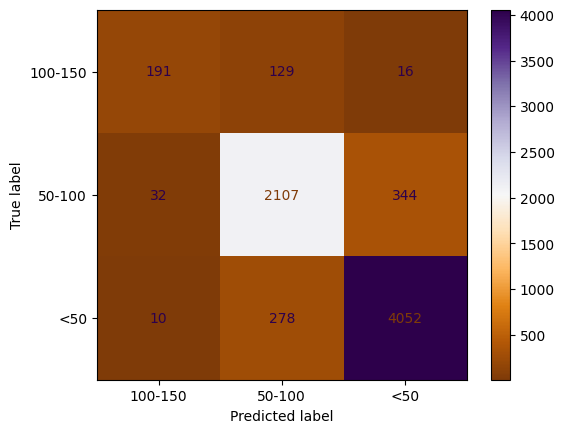

In [ ]:
ConfusionMatrixDisplay.from_predictions(y1_test, y1_pred, cmap='PuOr');


In [1230]:
le = LabelEncoder()
y1_train_enc = le.fit_transform(y1_train_res)

xgb_model = XGBClassifier(n_estimators=200, random_state=35)
xgb_model.fit(X_train_res, y1_train_enc)

# Predict and decode back to original string labels
y1_pred_xgb = le.inverse_transform(xgb_model.predict(X_test_final))

print("Weighted F1 Score:", f1_score(y1_test, y1_pred_xgb, average='weighted'))
print("Macro F1 Score:   ", f1_score(y1_test, y1_pred_xgb, average='macro'))
print("\nClassification Report:\n")
print(classification_report(y1_test, y1_pred_xgb))

Weighted F1 Score: 0.849745521075044
Macro F1 Score:    0.7595411497147596

Classification Report:

              precision    recall  f1-score   support

     100-150       0.63      0.54      0.58       336
      50-100       0.79      0.80      0.80      2483
         <50       0.90      0.90      0.90      4340

    accuracy                           0.85      7159
   macro avg       0.77      0.75      0.76      7159
weighted avg       0.85      0.85      0.85      7159



In [1232]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_res, y1_train_res)

y1_pred_knn = knn_model.predict(X_test_final)

print("Weighted F1 Score:", f1_score(y1_test, y1_pred_knn, average='weighted'))
print("Macro F1 Score:   ", f1_score(y1_test, y1_pred_knn, average='macro'))
print("\nClassification Report:\n")
print(classification_report(y1_test, y1_pred_knn))

Weighted F1 Score: 0.6666273287315536
Macro F1 Score:    0.5358352128783831

Classification Report:

              precision    recall  f1-score   support

     100-150       0.19      0.41      0.26       336
      50-100       0.55      0.70      0.62      2483
         <50       0.85      0.64      0.73      4340

    accuracy                           0.65      7159
   macro avg       0.53      0.58      0.54      7159
weighted avg       0.71      0.65      0.67      7159

